# Raisin Dataset: EDA + Gaussian Naive Bayes
# ML Lab
## Name :- Pushkar Kolhe
## Roll no :- 51
## Section-Batch :- A-A4
## Lab-7

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,ConfusionMatrixDisplay)

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_excel('Raisin_Dataset.xlsx')
print(df.head())

    Area  MajorAxisLength  MinorAxisLength  Eccentricity  ConvexArea  \
0  87524       442.246011       253.291155      0.819738       90546   
1  75166       406.690687       243.032436      0.801805       78789   
2  90856       442.267048       266.328318      0.798354       93717   
3  45928       286.540559       208.760042      0.684989       47336   
4  79408       352.190770       290.827533      0.564011       81463   

     Extent  Perimeter    Class  
0  0.758651   1184.040  Kecimen  
1  0.684130   1121.786  Kecimen  
2  0.637613   1208.575  Kecimen  
3  0.699599    844.162  Kecimen  
4  0.792772   1073.251  Kecimen  


## 1. Basic EDA

### 1.1 Head and Tail

In [3]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


### 1.2 Shape, columns and data types

In [5]:
print("Shape:", df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Shape: (900, 8)
Rows: 900 | Columns: 8


In [6]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter', 'Class']


In [7]:
df.dtypes

,0
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64
Class,object


### 1.3 Info, describe and transposed describe

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [9]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,900.0,87804.127778,39002.111390,25387.000000,59348.000000,78902.000000,105028.250000,235047.000000
MajorAxisLength,900.0,430.929950,116.035121,225.629541,345.442898,407.803951,494.187014,997.291941
MinorAxisLength,900.0,254.488133,49.988902,143.710872,219.111126,247.848409,279.888575,492.275279
Eccentricity,900.0,0.781542,0.090318,0.348730,0.741766,0.798846,0.842571,0.962124
ConvexArea,900.0,91186.090000,40769.290132,26139.000000,61513.250000,81651.000000,108375.750000,278217.000000
Extent,900.0,0.699508,0.053468,0.379856,0.670869,0.707367,0.734991,0.835455
Perimeter,900.0,1165.906636,273.764315,619.074000,966.410750,1119.509000,1308.389750,2697.753000


### 1.4 Null values and duplicates

In [11]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 2. Data Cleaning
- Null values: numeric columns are filled with the **median**, categorical columns with the **mode**.
- Duplicate rows are deleted.

In [13]:
# Fill null values
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object' or str(df[col].dtype) in ('str', 'string', 'category'):
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("Null values after filling:")
print(df.isnull().sum())

Null values after filling:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64


In [14]:
# Delete duplicate rows
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before:", before, "| Rows after:", df.shape[0])
print("Duplicates remaining:", df.duplicated().sum())

Rows before: 900 | Rows after: 900
Duplicates remaining: 0


## 3. Data Visualization

In [15]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Numerical columns:", num_cols)
sns.set_style("whitegrid")

Numerical columns: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


### 3.1 Count plot

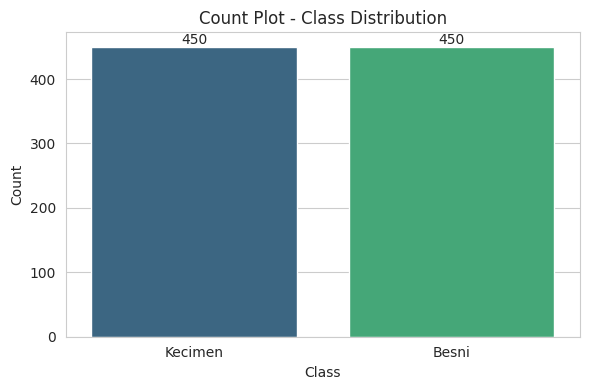

In [16]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Class', hue='Class', palette='viridis')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Count Plot - Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### 3.2 Bar plot (mean of each feature by class)

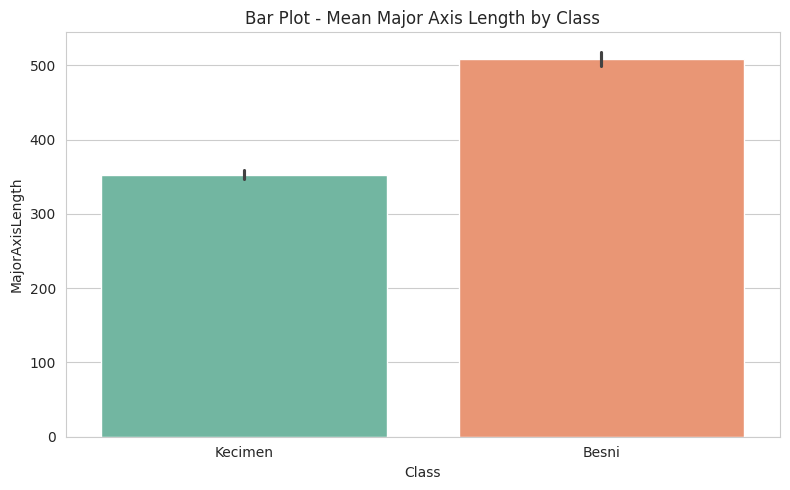

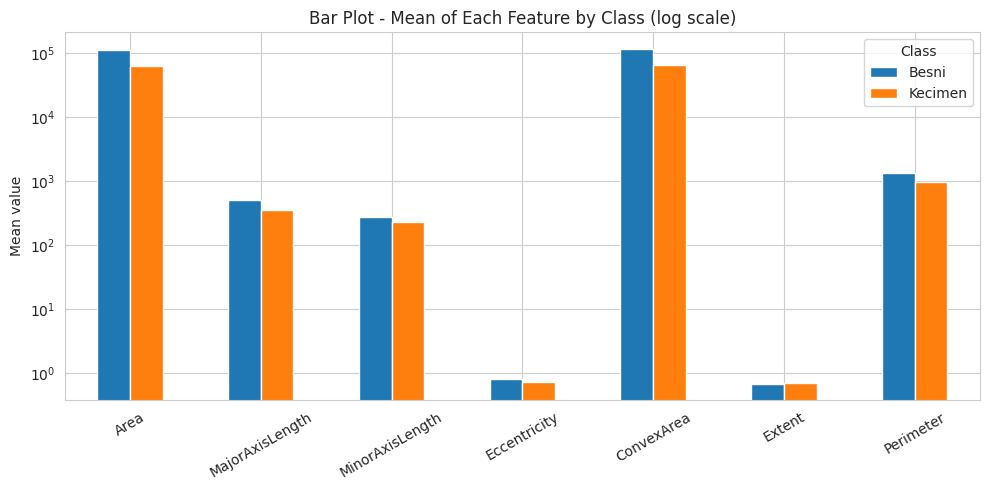

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Class', y='MajorAxisLength', hue='Class', palette='Set2')
plt.title('Bar Plot - Mean Major Axis Length by Class')
plt.tight_layout()
plt.show()

# Mean of all features per class
df.groupby('Class')[num_cols].mean().T.plot(kind='bar', figsize=(10, 5), logy=True)
plt.title('Bar Plot - Mean of Each Feature by Class (log scale)')
plt.ylabel('Mean value')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 3.3 Pie chart

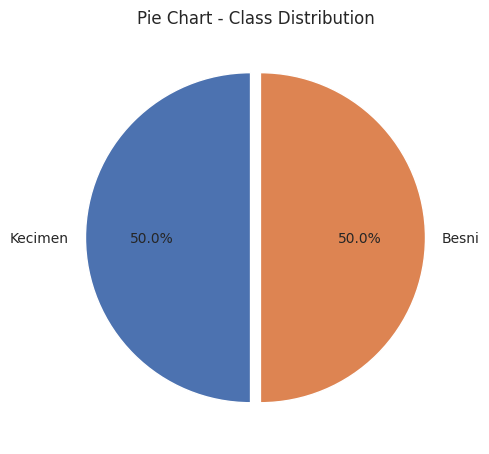

In [18]:
plt.figure(figsize=(5, 5))
df['Class'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90,
                                colors=['#4C72B0', '#DD8452'], explode=[0.03, 0.03])
plt.title('Pie Chart - Class Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 3.4 Histogram

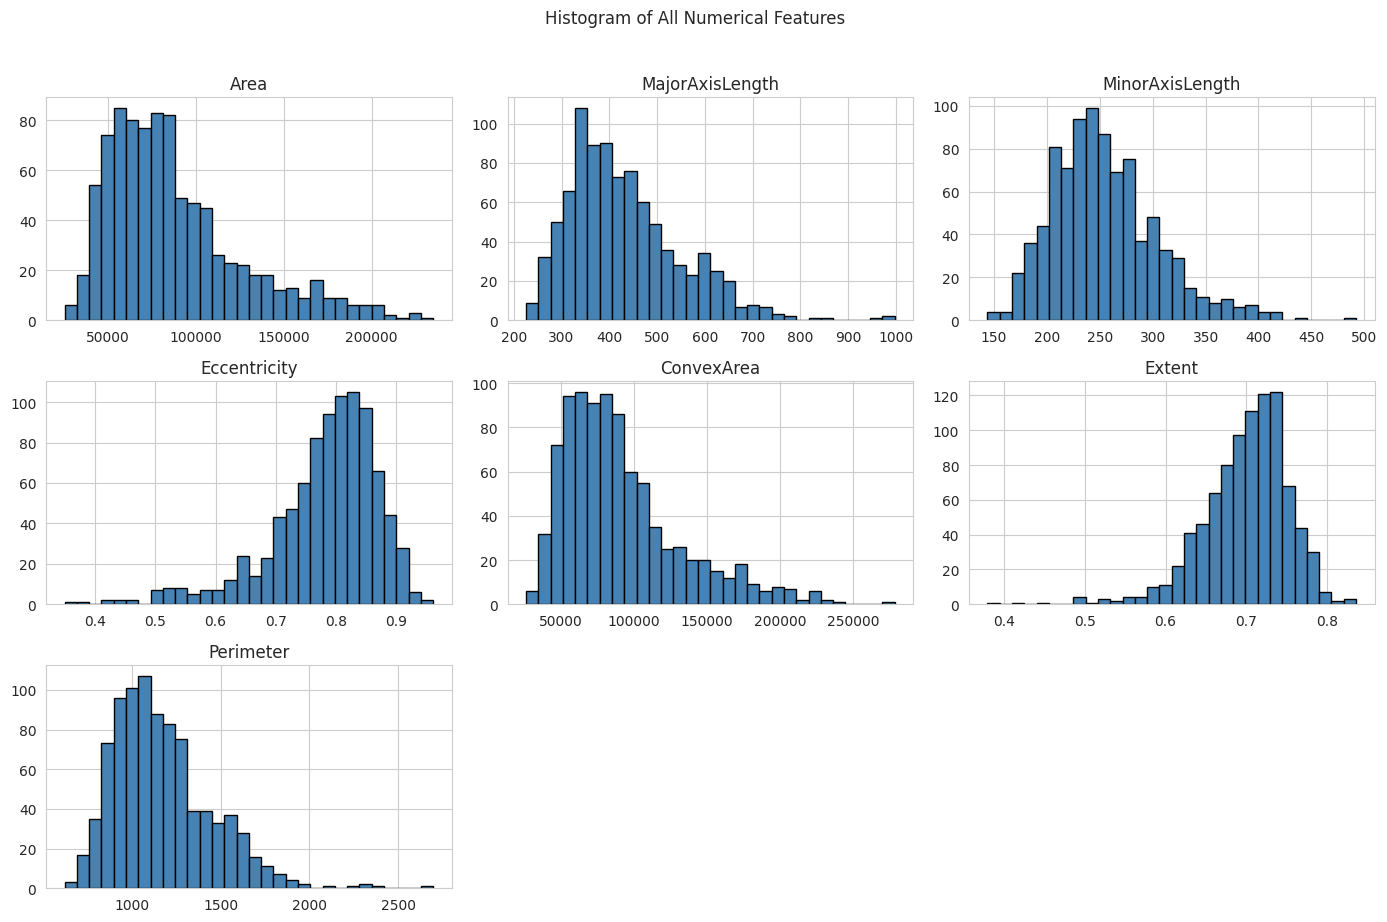

In [19]:
df[num_cols].hist(bins=30, figsize=(14, 9), edgecolor='black', color='steelblue')
plt.suptitle('Histogram of All Numerical Features', y=1.02)
plt.tight_layout()
plt.show()

### 3.5 Histogram + KDE

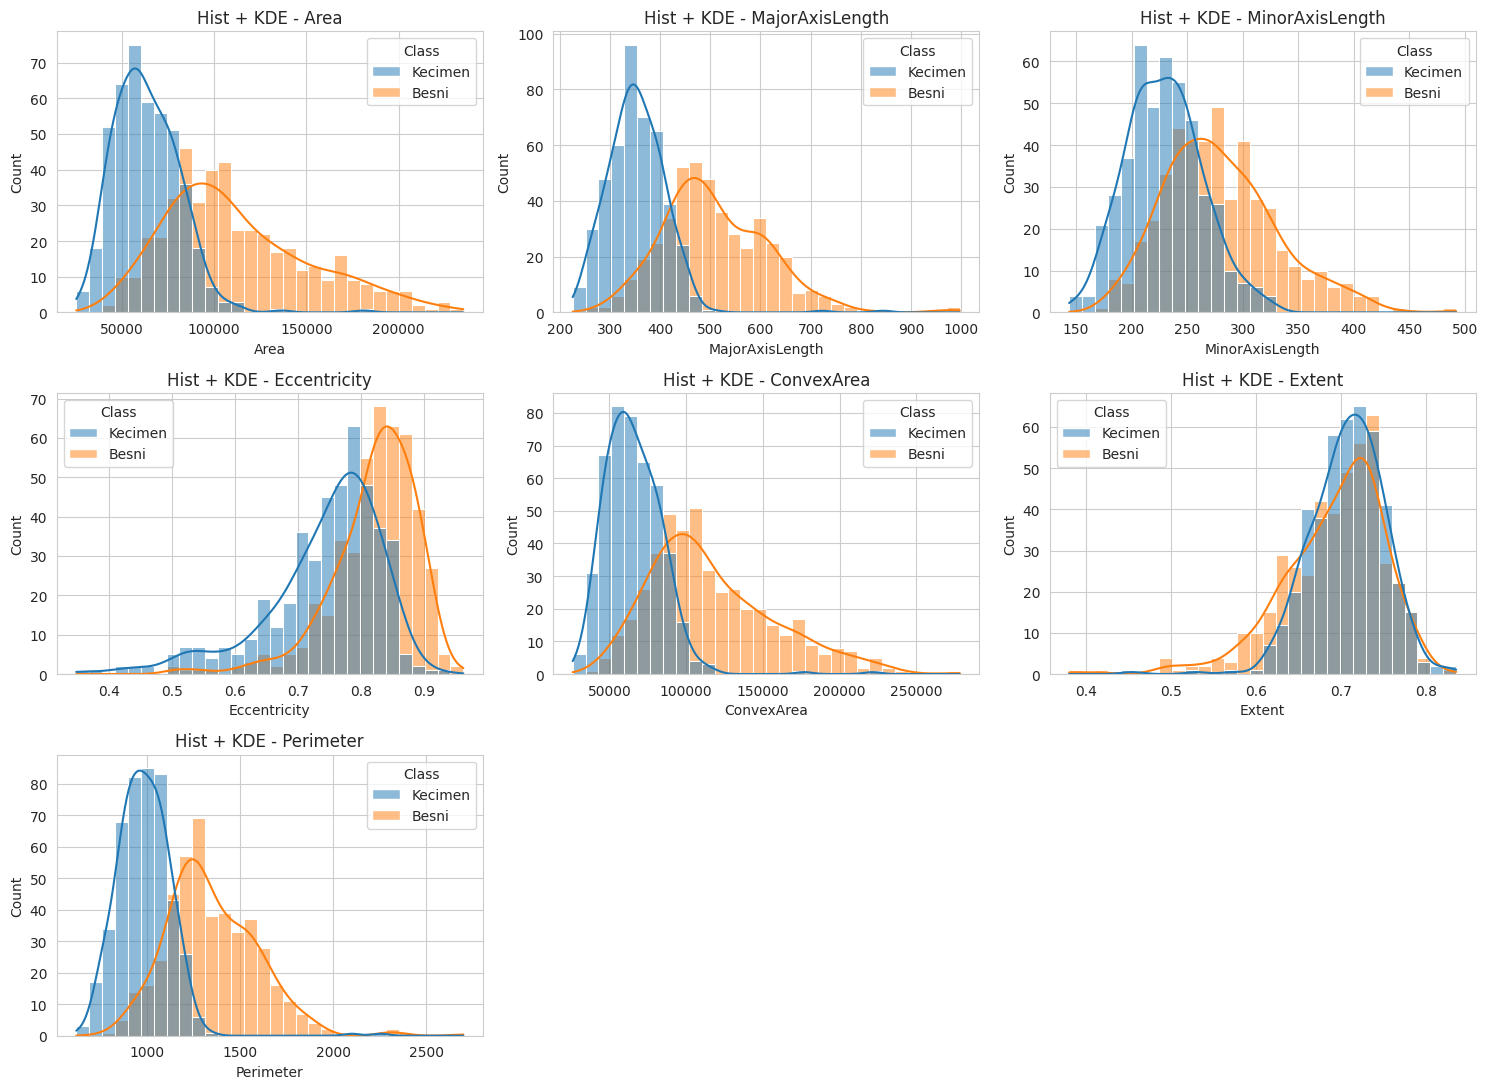

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Class', kde=True, bins=30, ax=axes[i])
    axes[i].set_title(f'Hist + KDE - {col}')
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

### 3.6 Box plot

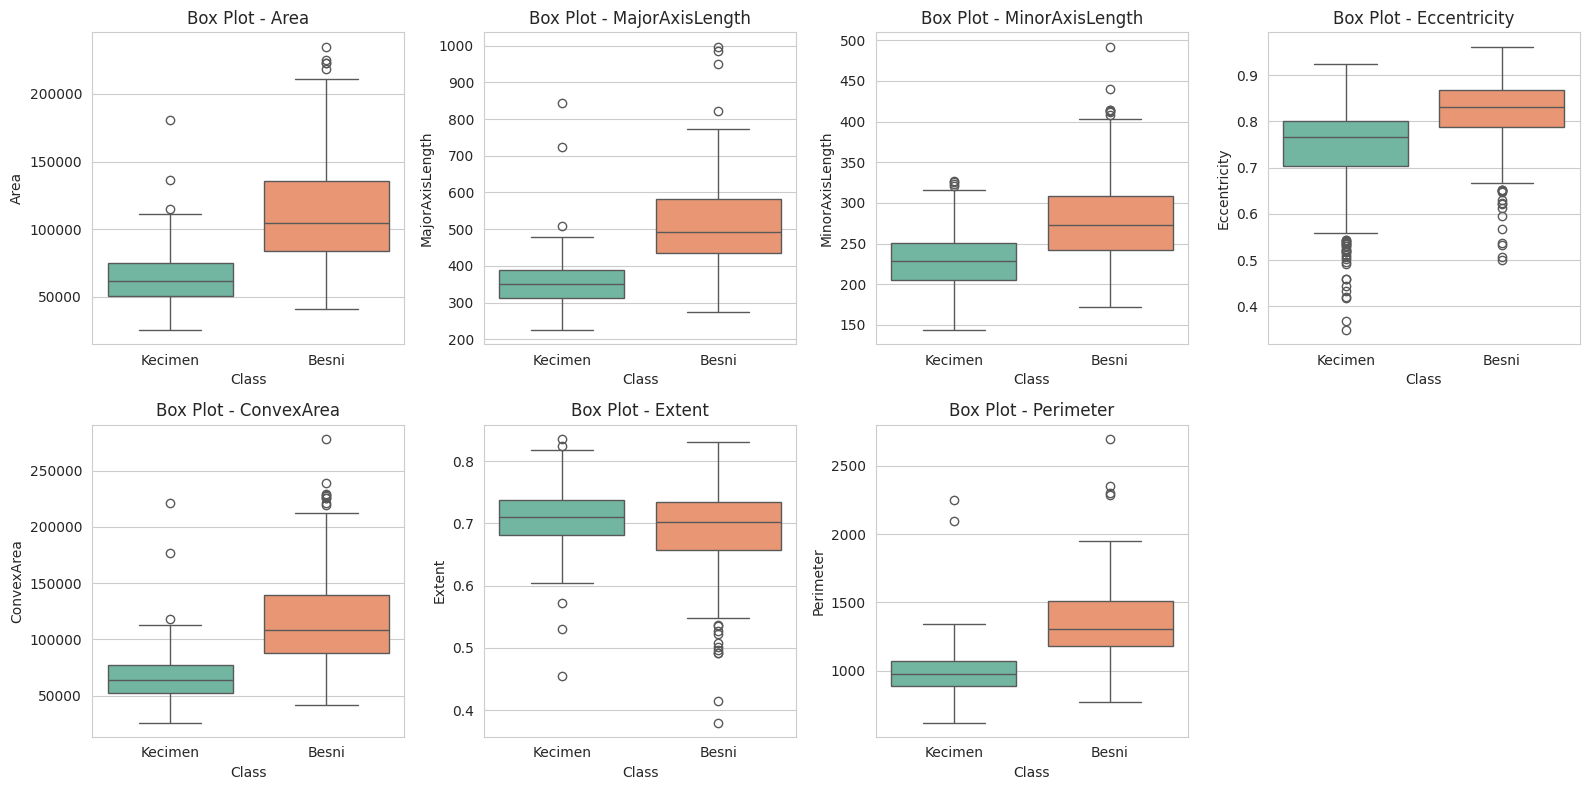

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Class', y=col, hue='Class', palette='Set2', ax=axes[i])
    axes[i].set_title(f'Box Plot - {col}')
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

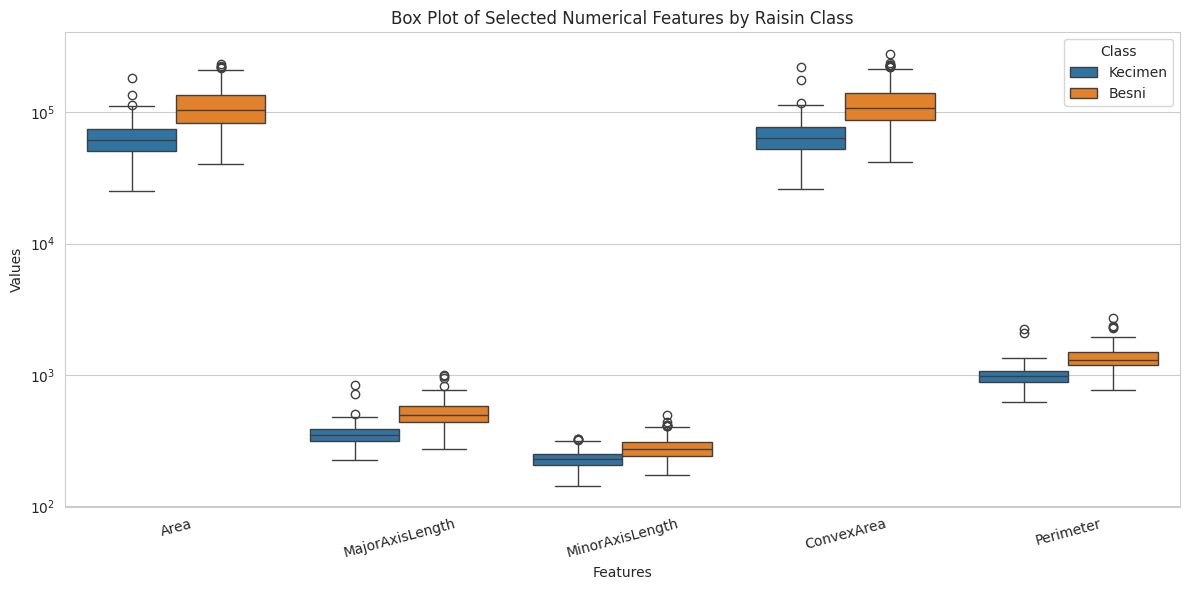

In [22]:
# Combined box plot of selected features by class (log scale, as in Lab 7)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.melt(id_vars='Class',
                         value_vars=['Area', 'MajorAxisLength', 'MinorAxisLength',
                                     'ConvexArea', 'Perimeter']),
            x='variable', y='value', hue='Class')
plt.title('Box Plot of Selected Numerical Features by Raisin Class')
plt.xlabel('Features')
plt.ylabel('Values')
plt.yscale('log')   # Area and ConvexArea are much larger than the other features
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 3.7 Heatmap (correlation matrix)

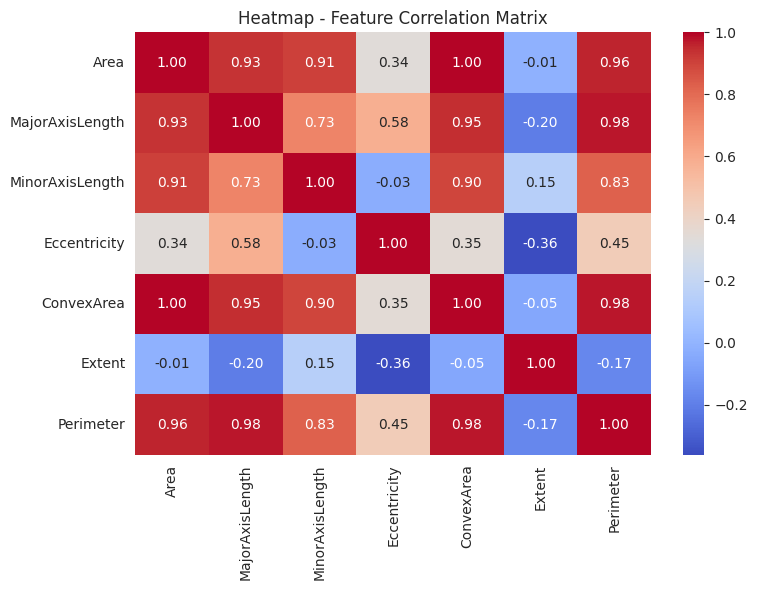

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap - Feature Correlation Matrix')
plt.tight_layout()
plt.show()

### 3.8 Scatter plot

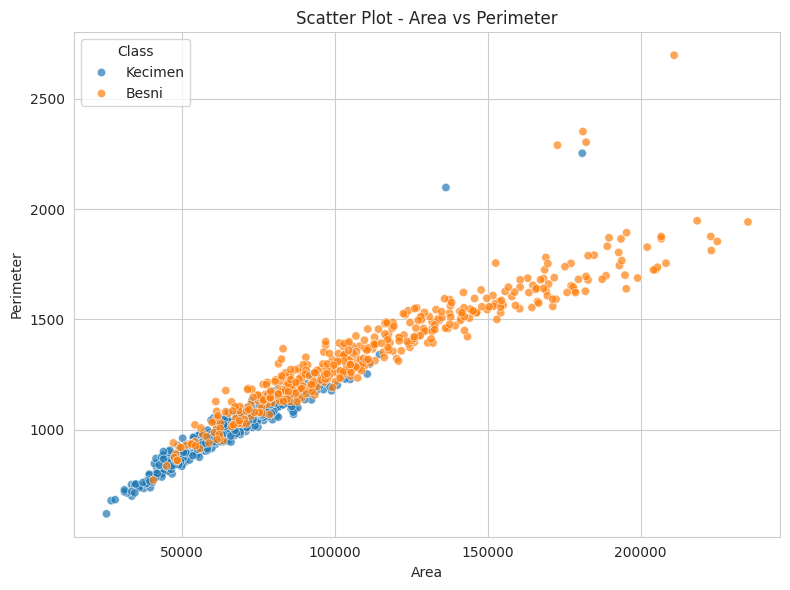

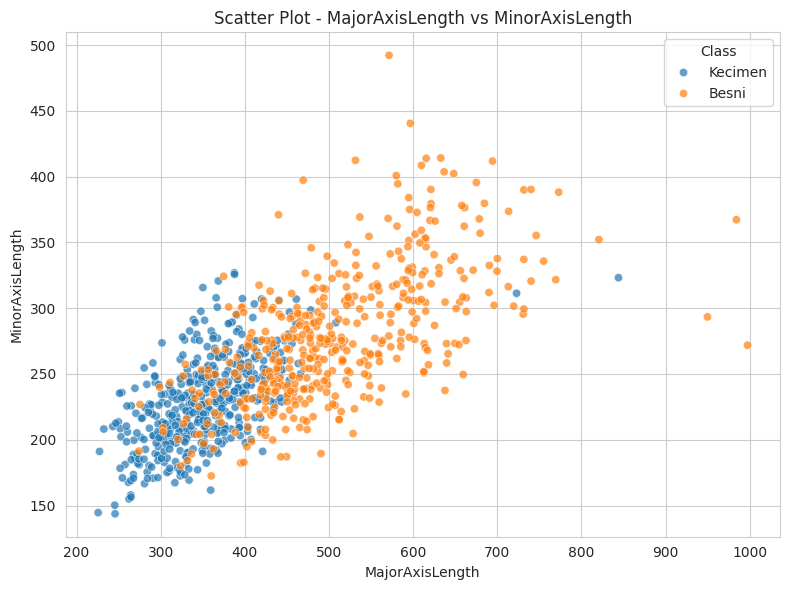

In [24]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Area', y='Perimeter', hue='Class', alpha=0.7)
plt.title('Scatter Plot - Area vs Perimeter')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='MajorAxisLength', y='MinorAxisLength', hue='Class', alpha=0.7)
plt.title('Scatter Plot - MajorAxisLength vs MinorAxisLength')
plt.tight_layout()
plt.show()

### 3.9 Pair plot

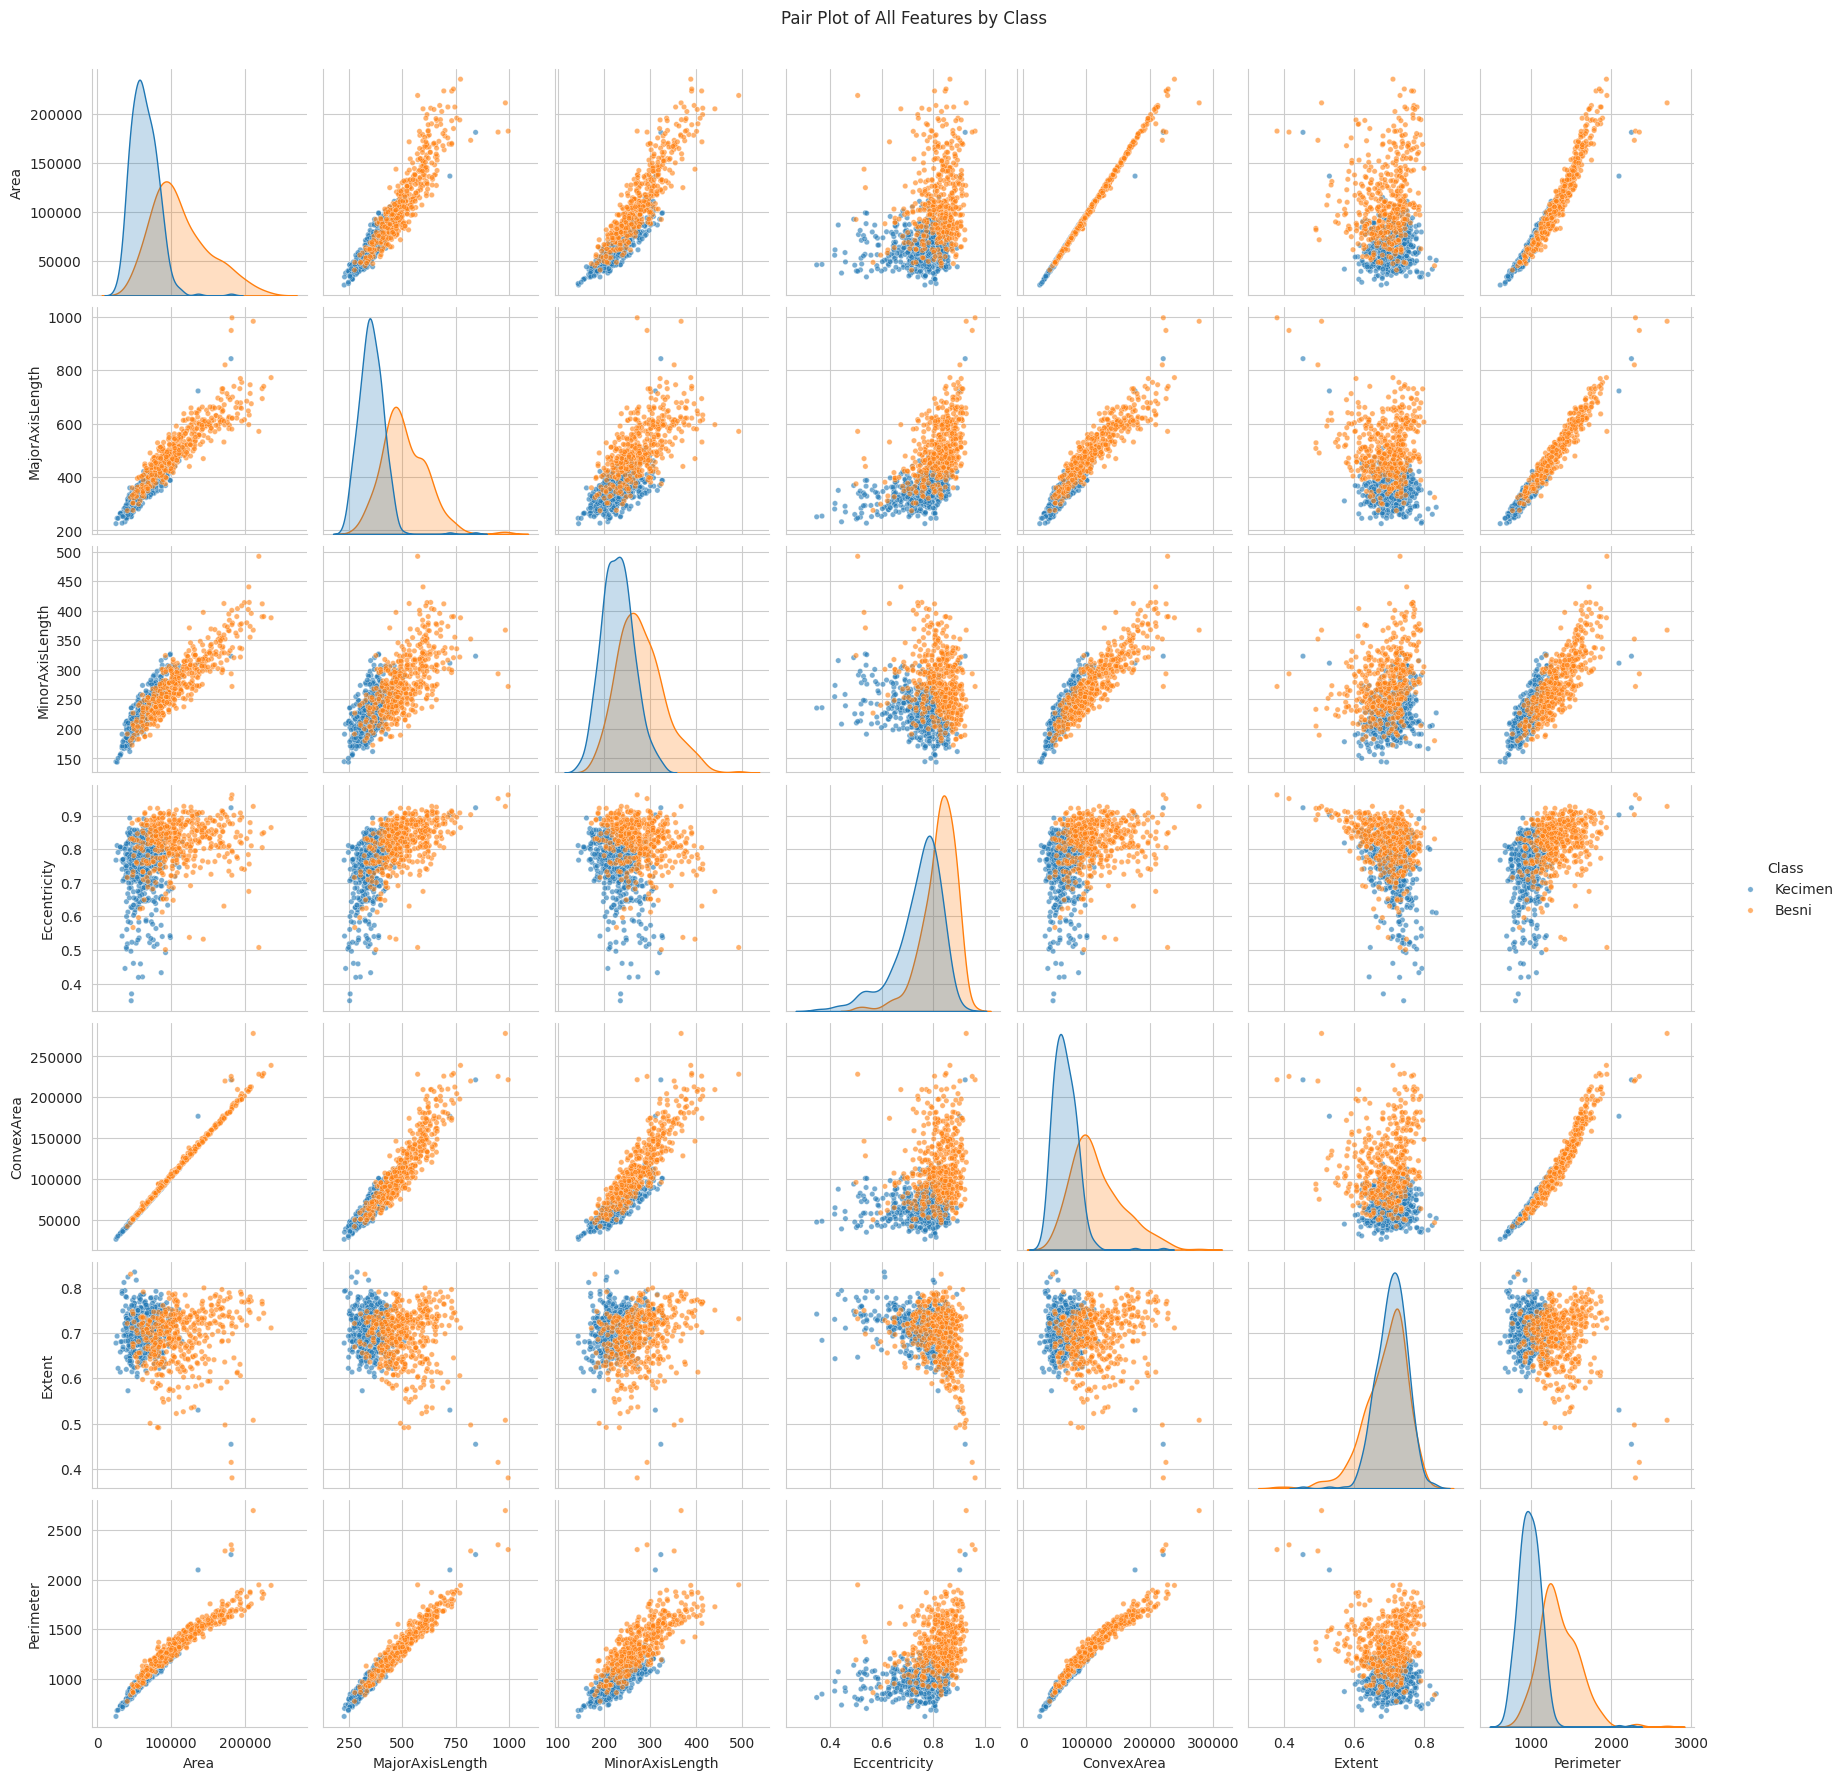

In [25]:
sns.pairplot(df, hue='Class', diag_kind='kde', corner=False,
             plot_kws={'alpha': 0.6, 's': 15})
plt.suptitle('Pair Plot of All Features by Class', y=1.02)
plt.show()

## 4. Lab 7: Naive Bayes Classification

### 4.1 Encode target label (Besni = 0, Kecimen = 1)

In [26]:
label_encoder = LabelEncoder()
df['Class_encoded'] = label_encoder.fit_transform(df['Class'])
print(df[['Class', 'Class_encoded']].head(5))
print("Unique encoded classes:",
      dict(zip(label_encoder.classes_,
               label_encoder.transform(label_encoder.classes_))))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
Unique encoded classes: {'Besni': np.int64(0), 'Kecimen': np.int64(1)}


### 4.2 Features and target

In [27]:
numerical_features = [c for c in df.select_dtypes(include=np.number).columns
                      if c != 'Class_encoded']
print("Numerical features:", numerical_features)

X = df[numerical_features]
y = df['Class_encoded']
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Numerical features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']
Shape of X: (900, 7)
Shape of y: (900,)


### 4.3 Train/test split (80:20)

In [28]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train_r.shape, "| Test:", X_test_r.shape)

Train: (720, 7) | Test: (180, 7)


### 4.4 Train Gaussian Naive Bayes

In [29]:
gnb_model = GaussianNB()
gnb_model.fit(X_train_r, y_train_r)

GaussianNB()

### 4.5 Predict on the test set

In [30]:
y_pred = gnb_model.predict(X_test_r)
print("Predicted labels:")
print(y_pred)

Predicted labels:
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


### 4.6 Actual vs predicted

In [31]:
comparison = pd.DataFrame({'Actual': y_test_r, 'Predicted': y_pred})
comparison["Actual class"] = label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted class"] = label_encoder.inverse_transform(comparison["Predicted"])
comparison.head(5)

,Actual,Predicted,Actual class,Predicted class
502,0,1,Besni,Kecimen
637,0,0,Besni,Besni
701,0,0,Besni,Besni
237,1,1,Kecimen,Kecimen
707,0,0,Besni,Besni


### 4.7 Evaluation metrics

In [32]:
accuracy  = accuracy_score(y_test_r, y_pred)
precision = precision_score(y_test_r, y_pred, average='weighted')
recall    = recall_score(y_test_r, y_pred, average='weighted')
f1        = f1_score(y_test_r, y_pred, average='weighted')

print("======MODEL PERFORMANCE===========")
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification report:\n")
print(classification_report(y_test_r, y_pred, target_names=label_encoder.classes_))

======MODEL PERFORMANCE===========
Accuracy: 0.8166666666666667
Accuracy (%): 81.66666666666667
Precision: 0.8387927618544444
Recall: 0.8166666666666667
F1 Score: 0.8136236704213862

Classification report:

              precision    recall  f1-score   support

       Besni       0.93      0.69      0.79        90
     Kecimen       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



### 4.8 Confusion matrix

In [33]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test_r,y_pred)
print("confusion matrix")
print(cm)

confusion matrix
[[62 28]
 [ 5 85]]


### 4.9 Training vs testing accuracy

Training Accuracy: 0.8263888888888888
Testing Accuracy: 0.8166666666666667


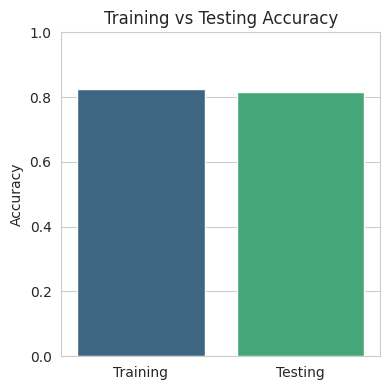

In [34]:
y_train_pred = gnb_model.predict(X_train_r)
y_test_pred  = gnb_model.predict(X_test_r)
train_accuracy = accuracy_score(y_train_r, y_train_pred)
test_accuracy  = accuracy_score(y_test_r, y_test_pred)
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

plt.figure(figsize=(4, 4))
sns.barplot(x=['Training', 'Testing'], y=[train_accuracy, test_accuracy],
            hue=['Training', 'Testing'], palette='viridis')
plt.ylim(0, 1)
plt.title('Training vs Testing Accuracy')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

In [35]:
GaussianNB(priors=None)

GaussianNB()

# Main_Hyperparameter

In [36]:
GaussianNB(var_smoothing=1e-9)

GaussianNB()

In [37]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [38]:
smoothing_values = [1e-12, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
results = []

for value in smoothing_values:
    gnb_model = GaussianNB(var_smoothing=value)
    gnb_model.fit(X_train_r, y_train_r)

    y_train_pred = gnb_model.predict(X_train_r)
    y_test_pred = gnb_model.predict(X_test_r)

    train_accuracy = accuracy_score(y_train_r, y_train_pred)
    test_accuracy = accuracy_score(y_test_r, y_test_pred)
    precision = precision_score(y_test_r, y_test_pred, zero_division=0)
    recall = recall_score(y_test_r, y_test_pred, zero_division=0)
    f1 = f1_score(y_test_r, y_test_pred, zero_division=0)

    results.append({
        'Smoothing Value': value,
        'Training Accuracy': train_accuracy,
        'Testing Accuracy': test_accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

results_df = pd.DataFrame(results)
print(results_df)

   Smoothing Value  Training Accuracy  Testing Accuracy  Precision    Recall  \
0     1.000000e-12           0.830556          0.833333   0.767857  0.955556   
1     1.000000e-10           0.826389          0.816667   0.752212  0.944444   
2     1.000000e-09           0.826389          0.816667   0.752212  0.944444   
3     1.000000e-08           0.826389          0.816667   0.752212  0.944444   
4     1.000000e-07           0.826389          0.811111   0.745614  0.944444   
5     1.000000e-06           0.825000          0.811111   0.745614  0.944444   
6     1.000000e-05           0.822222          0.811111   0.741379  0.955556   
7     1.000000e-04           0.818056          0.788889   0.720339  0.944444   
8     1.000000e-03           0.815278          0.788889   0.720339  0.944444   
9     1.000000e-02           0.813889          0.783333   0.714286  0.944444   

   F1 Score  
0  0.851485  
1  0.837438  
2  0.837438  
3  0.837438  
4  0.833333  
5  0.833333  
6  0.834951  
7  0.81

In [39]:
results_df = pd.DataFrame(
    results,
    columns=["var_smooothing", "Accuracy", "Precision", "Recall", "F1 Score"]
)

print(results_df)

   var_smooothing  Accuracy  Precision    Recall  F1 Score
0             NaN       NaN   0.767857  0.955556  0.851485
1             NaN       NaN   0.752212  0.944444  0.837438
2             NaN       NaN   0.752212  0.944444  0.837438
3             NaN       NaN   0.752212  0.944444  0.837438
4             NaN       NaN   0.745614  0.944444  0.833333
5             NaN       NaN   0.745614  0.944444  0.833333
6             NaN       NaN   0.741379  0.955556  0.834951
7             NaN       NaN   0.720339  0.944444  0.817308
8             NaN       NaN   0.720339  0.944444  0.817308
9             NaN       NaN   0.714286  0.944444  0.813397
